# NYC Taxi Times

**Author:** Clarice Mottet  

---

## Objective

Build a model to predict the total ride duration for NYC taxis

---

## Dataset
**Source:**
- kaggle


## Table of Contents

- [1. Load Data](#1-load-data)
- [2. Data Cleaning](#2-data-cleaning)
- [3. Exploratory Data Analysis](#3-exploratory-data-analysis)
- [4. Feature Engineering](#4-feature-engineering)
- [5. Modeling](#5-modeling)
- [6. Model Evaluation](#6-model-evaluation)


## Notes

- Random seed = 42
- Train/Test split = pre-determined by datasets given
- Evaluation metric = Root Mean Squared Log Error

# 1. Load Data

In [41]:
#libraries

import pandas as pd
import numpy as np
import os
from pathlib import Path

project_root = Path.cwd().parent          # if notebook is inside notebooks/


In [42]:
#import in the datasets
#quick look over

#establish  file path

raw_path = project_root / "data" / "raw"
os.listdir(raw_path)

df_test = pd.read_csv(raw_path / "test.csv", dtype = str)
df_train = pd.read_csv(raw_path / "train.csv", dtype = str)
df_sample = pd.read_csv(raw_path / "sample_submission.csv", dtype = str)

* Column Check:
train dataset has the columns "dropoff_datetime" and "trip_duration" which test does not

In [43]:
#perform columns check

# print(df_test.columns)
# print(df_train.columns)

list_test_col = list(df_test.columns)
list_train_col = list(df_train.columns)

list_all_col = list_test_col + list_train_col
list_all_col = list(set(list_all_col))
print(list_all_col)

list_test_doesnt = [x for x in list_all_col if x not in list_test_col]
print(list_test_doesnt)

list_train_doesnt = [x for x in list_all_col if x not in list_train_col]
# print(list_train_doesnt)

#so train has the resulting columns for me to be able to compare and train to, theres dropoff_datetime and trip duration



['id', 'pickup_latitude', 'vendor_id', 'passenger_count', 'dropoff_latitude', 'trip_duration', 'pickup_longitude', 'store_and_fwd_flag', 'pickup_datetime', 'dropoff_datetime', 'dropoff_longitude']
['trip_duration', 'dropoff_datetime']


# 3. Data Cleaning

* dtype
* nulls
* duplicates

* Data Type check:

In [45]:
# print(df_train.head())
# print(df_train.columns)

#need to identify dtypes
for col in df_train.columns:
    df_train[col] = df_train[col].str.strip()

#numeric columns
list_col_num = ['vendor_id', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
                'trip_duration']
list_col_date = ['pickup_datetime', 'dropoff_datetime']


In [46]:
# df_test.head()

In [47]:
# df_train.columns

* convert train and test to numeric

In [8]:
df_ = df_train.copy()

list_convert_num = [x for x in list_col_num if x in df_.columns]
df_[list_convert_num] = df_[list_convert_num].apply(pd.to_numeric)
df_train = df_.copy()

In [9]:
df_t = df_test.copy()

list_convert_num = [x for x in list_col_num if x in df_t.columns]
df_t[list_convert_num] = df_t[list_convert_num].apply(pd.to_numeric)
df_test = df_t.copy()

In [48]:
# df_test.columns

In [49]:
# df_test.dtypes

* convert train and test to datetime

In [12]:
df_ = df_train.copy()

list_convert_date = [x for x in list_col_date if x in df_.columns]
df_[list_convert_date] = df_[list_convert_date].apply(pd.to_datetime)
df_train = df_.copy()

In [13]:
df_train.dtypes

id                            object
vendor_id                      int64
pickup_datetime       datetime64[ns]
dropoff_datetime      datetime64[ns]
passenger_count                int64
pickup_longitude             float64
pickup_latitude              float64
dropoff_longitude            float64
dropoff_latitude             float64
store_and_fwd_flag            object
trip_duration                  int64
dtype: object

In [14]:
df_ = df_test.copy()

list_convert_date = [x for x in list_col_date if x in df_.columns]
df_[list_convert_date] = df_[list_convert_date].apply(pd.to_datetime)


In [15]:
df_.dtypes

id                            object
vendor_id                      int64
pickup_datetime       datetime64[ns]
passenger_count                int64
pickup_longitude             float64
pickup_latitude              float64
dropoff_longitude            float64
dropoff_latitude             float64
store_and_fwd_flag            object
dtype: object

* there are no nulls

In [17]:
df_train.isnull().sum()

id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

In [18]:
df_train.isna().sum()

id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

In [19]:
null_counts = df_train.isna().sum()
null_counts = null_counts[null_counts > 0]
print(null_counts)

Series([], dtype: int64)


In [20]:
null_counts = df_test.isna().sum()
null_counts = null_counts[null_counts > 0]
print(null_counts)

Series([], dtype: int64)


In [21]:
df_train.columns

Index(['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime',
       'passenger_count', 'pickup_longitude', 'pickup_latitude',
       'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag',
       'trip_duration'],
      dtype='object')

In [50]:
#target variables
var_target = ['dropoff_datetime','trip_duration']

# df_test.columns

* check to make sure trip duration is calculated properly, it is 

In [34]:
df_view = df_train.copy()
df_view['dur_calc'] = (df_view['dropoff_datetime'] - df_view['pickup_datetime']).dt.total_seconds().astype(int)

df_view.head()

df_view['check_dur'] = (df_view['trip_duration'] - df_view['dur_calc']).abs()
df_view_ = df_view[df_view['check_dur']!=0]
# df_view_.head()
df_test.columns

Index(['id', 'vendor_id', 'pickup_datetime', 'passenger_count',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'store_and_fwd_flag'],
      dtype='object')

* there are no duplicates by the ID variabe in both train and test

* there are dupliactes by all other fields (1 in test, 7 in train)

In [37]:
#check for duplicates

df_view = df_test.copy()
df_view.drop_duplicates(subset = ['pickup_datetime', 'passenger_count',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'store_and_fwd_flag'], inplace = True)



In [51]:
df_view = df_train.copy()
df_view.drop_duplicates(subset = ['pickup_datetime', 'passenger_count',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'store_and_fwd_flag'], inplace = True)



* check for invalid values

In [52]:
df_train.describe()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
count,1458644,1458644,1458644,1458644,1458644,1458644,1458644,1458644,1458644,1458644,1458644
unique,1458644,2,1380222,1380377,10,23047,45245,33821,62519,2,7417
top,id2875421,2,2016-03-04 08:07:34,2016-02-19 19:25:04,1,-73.982200622558594,40.774101257324219,-73.982330322265625,40.774311065673828,N,368
freq,1,780302,5,5,1033540,633,414,443,269,1450599,1624


* checking ranges for variables

# Train
* passenger_count - no issues

# Test
* passenger_count - no issues

<Axes: >

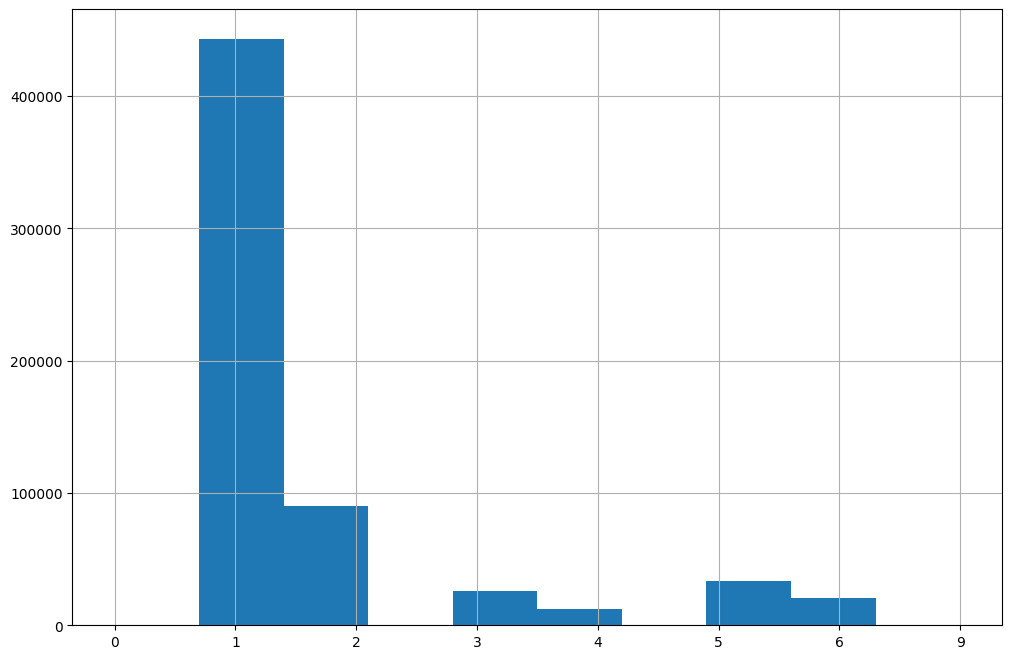

In [ ]:

df_train.sort_values(by = ['passenger_count'], inplace = True)
df_train['passenger_count'].hist(figsize=(12,8))